In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df = pd.read_csv("retail_sales_dataset.csv")

df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [5]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

Dataset Shape: (1000, 9)

Column Names:
Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB


In [6]:
df.isnull().sum()

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

In [7]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [8]:
df['Date'] = pd.to_datetime(df['Date'])

df['Date'].dtype

dtype('<M8[us]')

In [9]:
df.describe()

,Transaction ID,Date,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,2023-07-03 00:25:55.200000,41.39200,2.514000,179.890000,456.000000
min,1.000000,2023-01-01 00:00:00,18.00000,1.000000,25.000000,25.000000
25%,250.750000,2023-04-08 00:00:00,29.00000,1.000000,30.000000,60.000000
50%,500.500000,2023-06-29 12:00:00,42.00000,3.000000,50.000000,135.000000
75%,750.250000,2023-10-04 00:00:00,53.00000,4.000000,300.000000,900.000000
max,1000.000000,2024-01-01 00:00:00,64.00000,4.000000,500.000000,2000.000000
std,288.819436,NaN,13.68143,1.132734,189.681356,559.997632


In [10]:
df['Product Category'].value_counts()

Product Category
Clothing       351
Electronics    342
Beauty         307
Name: count, dtype: int64

In [11]:
df['Gender'].value_counts()

Gender
Female    510
Male      490
Name: count, dtype: int64

In [12]:
df['Month'] = df['Date'].dt.month

monthly_sales = df.groupby('Month')['Total Amount'].sum()

monthly_sales

Month
1     36980
2     44060
3     28990
4     33870
5     53150
6     36715
7     35465
8     36960
9     23620
10    46580
11    34920
12    44690
Name: Total Amount, dtype: int64

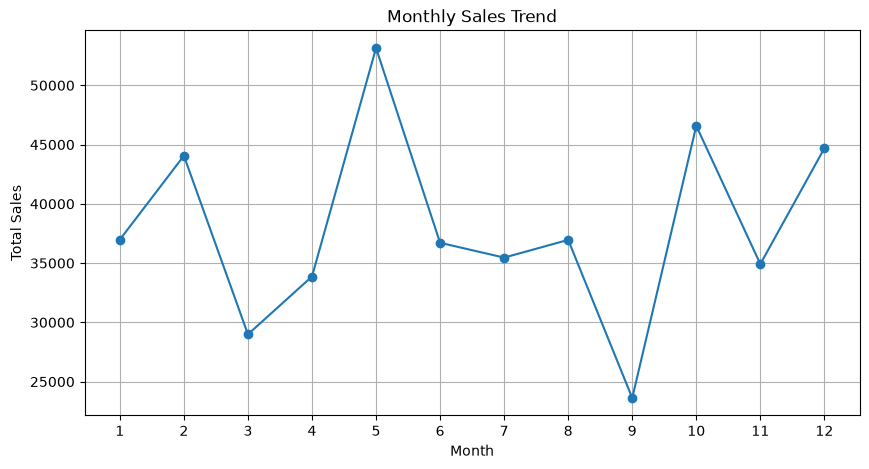

In [13]:
plt.figure(figsize=(10, 5))

plt.plot(monthly_sales.index, monthly_sales.values, marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')

plt.xticks(range(1, 13))
plt.grid(True)

plt.show()

In [14]:
category_sales = df.groupby('Product Category')['Total Amount'].sum()

category_sales

Product Category
Beauty         143515
Clothing       155580
Electronics    156905
Name: Total Amount, dtype: int64

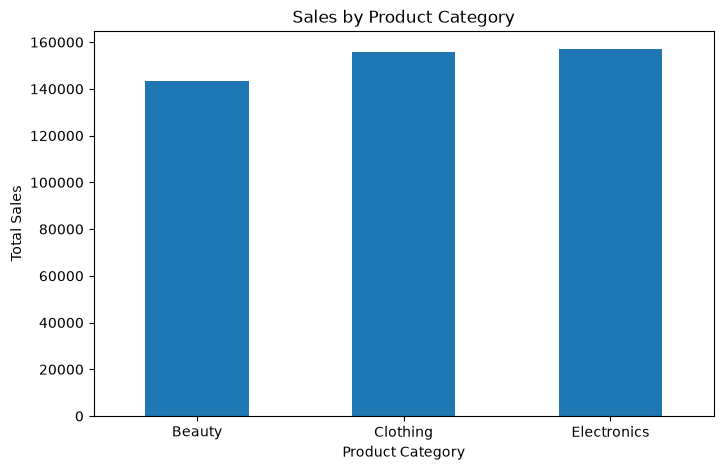

In [15]:
plt.figure(figsize=(8, 5))

category_sales.plot(kind='bar')

plt.title('Sales by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales')

plt.xticks(rotation=0)
plt.show()

In [16]:
gender_sales = df.groupby('Gender')['Total Amount'].sum()

gender_sales

Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64

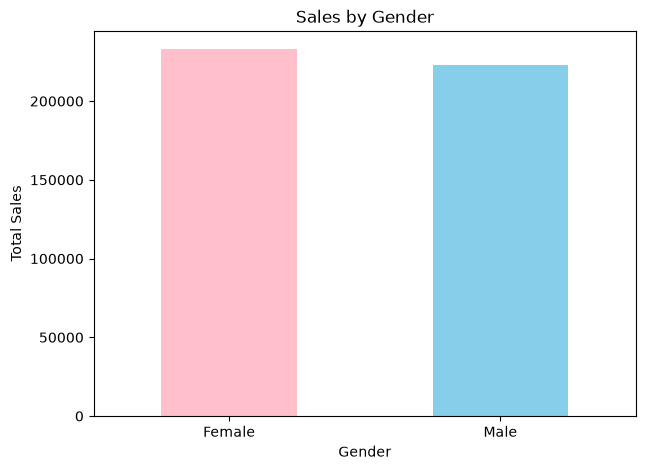

In [17]:
plt.figure(figsize=(7, 5))

gender_sales.plot(kind='bar', color=['pink', 'skyblue'])

plt.title('Sales by Gender')
plt.xlabel('Gender')
plt.ylabel('Total Sales')

plt.xticks(rotation=0)
plt.show()

In [18]:
df['Age Group'] = pd.cut(
    df['Age'],
    bins=[17, 25, 35, 45, 55, 65],
    labels=['18-25', '26-35', '36-45', '46-55', '56-65']
)

age_group_sales = df.groupby('Age Group', observed=False)['Total Amount'].sum()

age_group_sales

Age Group
18-25     84550
26-35     98480
36-45     91870
46-55    100690
56-65     80410
Name: Total Amount, dtype: int64

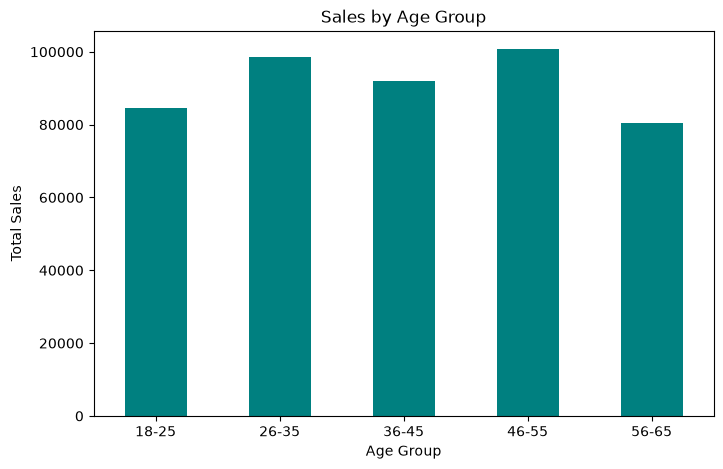

In [19]:
plt.figure(figsize=(8, 5))

age_group_sales.plot(kind='bar', color='teal')

plt.title('Sales by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Total Sales')

plt.xticks(rotation=0)
plt.show()

In [20]:
category_quantity = df.groupby('Product Category')['Quantity'].sum()

category_quantity

Product Category
Beauty         771
Clothing       894
Electronics    849
Name: Quantity, dtype: int64

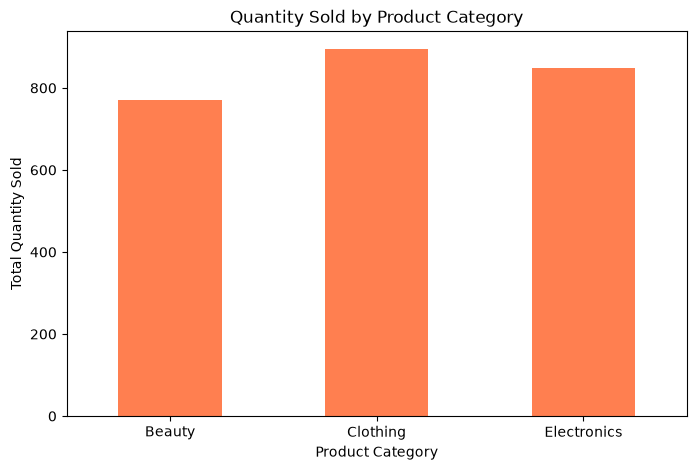

In [21]:
plt.figure(figsize=(8, 5))

category_quantity.plot(kind='bar', color='coral')

plt.title('Quantity Sold by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Quantity Sold')

plt.xticks(rotation=0)
plt.show()

In [22]:
average_sales = df['Total Amount'].mean()

print("Average Sales per Transaction:", average_sales)

Average Sales per Transaction: 456.0


In [23]:
total_revenue = df['Total Amount'].sum()
total_transactions = df['Transaction ID'].nunique()

print("Total Revenue:", total_revenue)
print("Total Transactions:", total_transactions)

Total Revenue: 456000
Total Transactions: 1000


In [24]:
print("Highest Transaction Amount:", df['Total Amount'].max())

print("Lowest Transaction Amount:", df['Total Amount'].min())

Highest Transaction Amount: 2000
Lowest Transaction Amount: 25


In [25]:
correlation = df[['Age', 'Quantity', 'Price per Unit', 'Total Amount']].corr()

correlation

,Age,Quantity,Price per Unit,Total Amount
Age,1.000000,-0.023737,-0.038423,-0.060568
Quantity,-0.023737,1.000000,0.017501,0.373707
Price per Unit,-0.038423,0.017501,1.000000,0.851925
Total Amount,-0.060568,0.373707,0.851925,1.000000


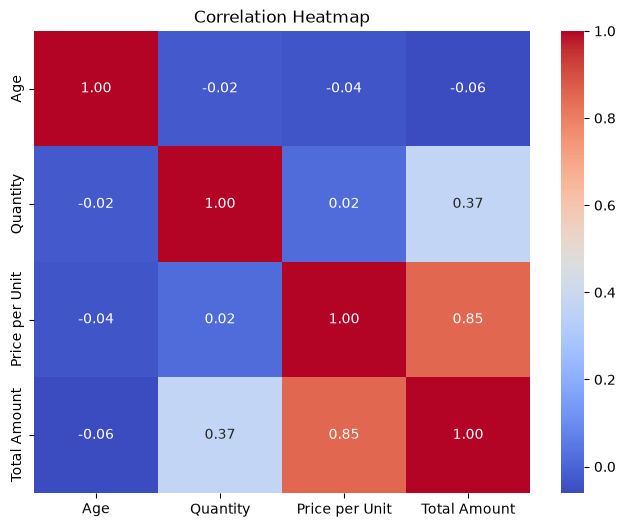

In [26]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

In [27]:
top_transactions = df.nlargest(5, 'Total Amount')

top_transactions[['Transaction ID', 'Product Category', 'Quantity', 'Total Amount']]

,Transaction ID,Product Category,Quantity,Total Amount
14,15,Electronics,4,2000
64,65,Electronics,4,2000
71,72,Electronics,4,2000
73,74,Beauty,4,2000
88,89,Electronics,4,2000


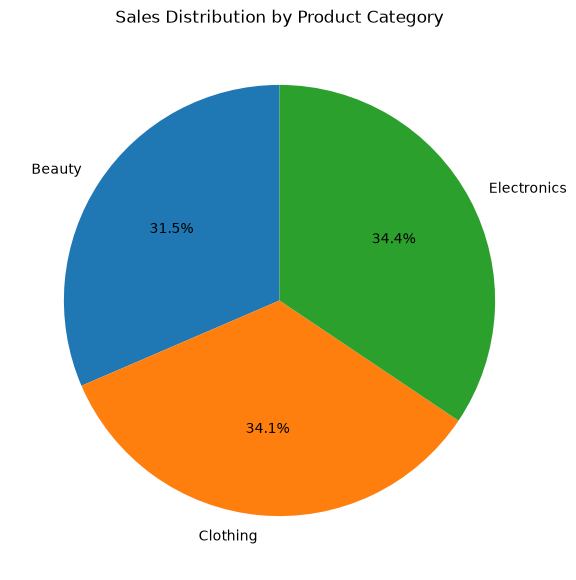

In [28]:
plt.figure(figsize=(7, 7))

category_sales.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Sales Distribution by Product Category')
plt.ylabel('')

plt.show()

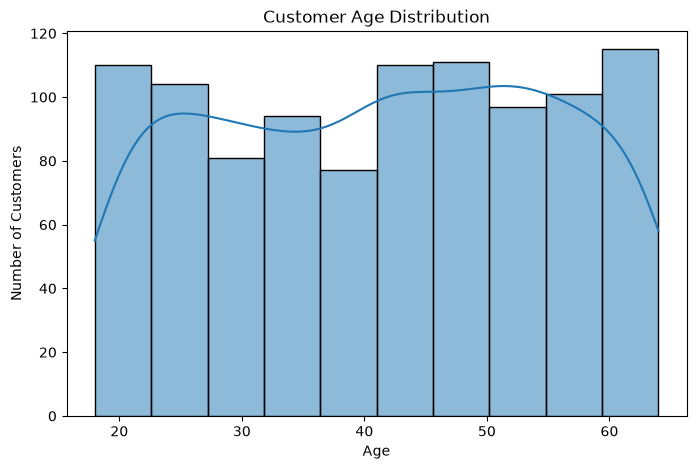

In [29]:
plt.figure(figsize=(8, 5))

sns.histplot(df['Age'], bins=10, kde=True)

plt.title('Customer Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Customers')

plt.show()

In [30]:
print("Final Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Final Dataset Shape: (1000, 11)

Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
Month               0
Age Group           0
dtype: int64

Duplicate Rows: 0


In [31]:
df[['Age', 'Quantity', 'Price per Unit', 'Total Amount']].agg(
    ['mean', 'median', lambda x: x.mode()[0], 'std']
)

,Age,Quantity,Price per Unit,Total Amount
mean,41.39200,2.514000,179.890000,456.000000
median,42.00000,3.000000,50.000000,135.000000
<lambda>,43.00000,4.000000,50.000000,50.000000
std,13.68143,1.132734,189.681356,559.997632


In [32]:
df['Quarter'] = df['Date'].dt.quarter

quarterly_sales = df.groupby('Quarter')['Total Amount'].sum()

quarterly_sales

Quarter
1    110030
2    123735
3     96045
4    126190
Name: Total Amount, dtype: int64

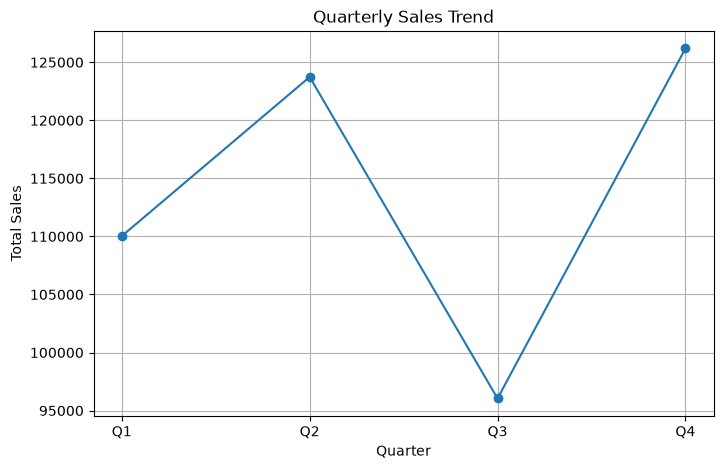

In [33]:
plt.figure(figsize=(8, 5))

plt.plot(
    quarterly_sales.index,
    quarterly_sales.values,
    marker='o',
    linestyle='-'
)

plt.title('Quarterly Sales Trend')
plt.xlabel('Quarter')
plt.ylabel('Total Sales')

plt.xticks([1, 2, 3, 4], ['Q1', 'Q2', 'Q3', 'Q4'])
plt.grid(True)

plt.show()

Quarterly Sales Trend – Insights
- Q4 recorded the highest sales of ₹1,26,190.
- Q3 recorded the lowest sales of ₹96,045.
- Sales increased significantly in Q4 compared to Q3.
- Q2 also showed strong sales performance.
- The business should focus on improving sales during Q3.

Business Recommendations

1. Focus on improving sales during Q3, as it recorded the lowest quarterly revenue.
2. Increase marketing efforts for Electronics and Clothing, which generate the highest category sales.
3. Target the 46–55 age group with personalized offers, as this group recorded the highest sales.
4. Promote Beauty products to improve their overall sales performance.
5. Analyze monthly sales trends to plan seasonal promotions and inventory effectively.
6. Maintain customer engagement through discounts, loyalty programs, and targeted campaigns.

Conclusion

This Exploratory Data Analysis (EDA) project analyzed a retail sales dataset containing 1,000 transactions.

Key findings:
- Total revenue generated was ₹456,000.
- Electronics generated the highest category sales.
- Q4 recorded the highest quarterly sales.
- The 46–55 age group contributed the highest sales among age groups.
- Quantity and total amount showed a positive correlation.

The analysis helped identify sales trends, customer behavior, and opportunities for business improvement.